# Chapter 12 — Zeek·Snort 로그 구조와 웹 로그 분석 (실습)

## 실습 목표
1. 합성 Zeek conn.log·http.log 로드·결합
2. Apache combined log 정규식 파싱
3. SQLi·XSS·Path traversal 룰 적용
4. 의심 IP 추출

In [1]:
# 파트별 노트북은 같은 종류의 공통 데이터·모델 작업 폴더를 사용합니다.
from pathlib import Path as _BookPath
import os as _book_os
_book_cwd = _BookPath.cwd()
if (_book_cwd.name in {"part1", "part2", "part3", "part4"}
        and _book_cwd.parent.name in {"instructor", "exercises", "solutions"}):
    _book_os.chdir(_book_cwd.parent)


In [2]:
# 첫 사용시에만 주석 해제하여 실행 (Colab/venv 환경에 따라 일부는 이미 설치됨)
# !pip install -q pandas
# !pip install -q numpy

In [3]:
import re
import pandas as pd
import numpy as np
from io import StringIO
rng = np.random.default_rng(42)

In [4]:
# === 한글 폰트 설정 (matplotlib) ===
from pathlib import Path
import matplotlib
from matplotlib import font_manager
for fp in ['/usr/share/fonts/truetype/nanum/NanumGothic.ttf',
           '/usr/share/fonts/truetype/nanum/NanumBarunGothic.ttf']:
    if Path(fp).exists():
        font_manager.fontManager.addfont(fp)
        matplotlib.rcParams['font.family'] = font_manager.FontProperties(fname=fp).get_name()
        break
matplotlib.rcParams['axes.unicode_minus'] = False

---
## Step 1. 합성 Zeek conn.log / http.log 생성·로드

In [5]:
def make_uid(): return ''.join(rng.choice(list('abcdefghij0123456789'), size=10))

# 2024-07-05 13:00:00 UTC. Apache 예제는 같은 시각을 +0900 으로 적으므로
# 두 소스를 그대로 합치면 9시간이 어긋납니다. Step 3 에서 UTC 로 맞춥니다.
BASE_EPOCH = 1720184400.0
rows_conn, rows_http = [], []
for _ in range(200):
    uid = make_uid()
    src = f'10.0.0.{rng.integers(1, 50)}'
    dst = f'93.184.216.{rng.integers(1, 250)}'
    # Zeek 은 ts 를 에포크 초(UTC)로 기록합니다. 13장 상관 분석의 시간 축이 됩니다.
    ts_epoch = BASE_EPOCH + float(rng.integers(0, 3600)) + round(float(rng.random()), 3)
    rows_conn.append({'ts': ts_epoch,
                      'uid': uid, 'id.orig_h': src, 'id.resp_h': dst,
                      'id.resp_p': int(rng.choice([80, 443])),
                      'proto': 'tcp', 'service': 'http' if rng.random() > 0.5 else 'ssl',
                      'duration': round(rng.uniform(0.1, 10), 3),
                      'orig_bytes': int(rng.integers(100, 50_000)),
                      'conn_state': 'SF'})
    if rng.random() > 0.3:  # 일부에만 HTTP
        rows_http.append({'uid': uid, 'method': rng.choice(['GET','POST']),
                          'host': rng.choice(['example.com','google.com','attacker.com']),
                          'uri': rng.choice(['/index.html','/login','/admin?cmd=ls','/?id=1 UNION SELECT *']),
                          'status_code': int(rng.choice([200, 200, 200, 401, 404, 500]))})
conn = pd.DataFrame(rows_conn)
http = pd.DataFrame(rows_http)
merged = conn.merge(http, on='uid', how='left')
print(f'conn={len(conn)}, http={len(http)}, merged={len(merged)}')
merged.head()

conn=200, http=125, merged=200


,ts,uid,id.orig_h,id.resp_h,id.resp_p,proto,service,duration,orig_bytes,conn_state,method,host,uri,status_code
0,1.720187e+09,b53ii7b3eb,10.0.0.26,93.184.216.243,443,tcp,ssl,4.559,25067,SF,GET,attacker.com,/admin?cmd=ls,200.0
1,1.720187e+09,60ijeb17b7,10.0.0.41,93.184.216.69,443,tcp,http,8.942,17790,SF,POST,example.com,/login,200.0
2,1.720188e+09,ja0d4384h9,10.0.0.21,93.184.216.82,80,tcp,ssl,1.386,34355,SF,NaN,NaN,NaN,NaN
3,1.720187e+09,j138id624b,10.0.0.16,93.184.216.192,443,tcp,ssl,6.857,19435,SF,NaN,NaN,NaN,NaN
4,1.720186e+09,6d6a5553j4,10.0.0.14,93.184.216.195,80,tcp,ssl,1.234,22036,SF,POST,attacker.com,/admin?cmd=ls,200.0


---
## Step 2. Apache combined 로그 파싱

In [6]:
sample_log = '''10.0.0.5 - - [05/Jul/2024:13:45:12 +0900] "GET /index.html HTTP/1.1" 200 1234 "-" "Mozilla/5.0"
10.0.0.99 - - [05/Jul/2024:13:45:13 +0900] "GET /admin?cmd=cat+/etc/passwd HTTP/1.1" 403 234 "-" "sqlmap/1.5"
10.0.0.99 - - [05/Jul/2024:13:45:14 +0900] "POST /login HTTP/1.1" 401 100 "-" "nikto/2.1"
10.0.0.5 - - [05/Jul/2024:13:45:15 +0900] "GET /search?q=<script>alert(1)</script> HTTP/1.1" 200 500 "-" "Mozilla/5.0"
10.0.0.99 - - [05/Jul/2024:13:45:16 +0900] "GET /../etc/passwd HTTP/1.1" 404 100 "-" "curl/7.0"
'''
PATTERN = re.compile(
    r'(?P<ip>\S+) \S+ \S+ \[(?P<time>[^\]]+)\] '
    r'"(?P<method>\S+) (?P<uri>\S+) (?P<proto>\S+)" '
    r'(?P<status>\d+) (?P<bytes>\S+) '
    r'"(?P<referer>[^"]*)" "(?P<ua>[^"]*)"'
)
records = [m.groupdict() for line in sample_log.strip().splitlines() if (m := PATTERN.match(line))]
web = pd.DataFrame(records)
web['status'] = web['status'].astype(int)
web

,ip,time,method,uri,proto,status,bytes,referer,ua
0,10.0.0.5,05/Jul/2024:13:45:12 +0900,GET,/index.html,HTTP/1.1,200,1234,-,Mozilla/5.0
1,10.0.0.99,05/Jul/2024:13:45:13 +0900,GET,/admin?cmd=cat+/etc/passwd,HTTP/1.1,403,234,-,sqlmap/1.5
2,10.0.0.99,05/Jul/2024:13:45:14 +0900,POST,/login,HTTP/1.1,401,100,-,nikto/2.1
3,10.0.0.5,05/Jul/2024:13:45:15 +0900,GET,/search?q=<script>alert(1)</script>,HTTP/1.1,200,500,-,Mozilla/5.0
4,10.0.0.99,05/Jul/2024:13:45:16 +0900,GET,/../etc/passwd,HTTP/1.1,404,100,-,curl/7.0


---
## Step 3. 통합 정규화 — 13장이 쓸 공통 스키마

Zeek 은 에포크 초, Apache 는 `+0900` 오프셋으로 시각을 적습니다. 표기가 다른 두 소스를
그대로 이어 붙이면 같은 순간이 9시간 어긋나 상관 분석이 틀어집니다. 본문 12.4절의
`normalize()` 로 **`ts`(UTC)·`src`·`dst`·`event`** 공통 열을 만듭니다.

파싱 실패는 정상 이벤트로 넘기지 않고 `errors='raise'` 로 즉시 드러냅니다.

In [7]:
def normalize(df, source: str) -> pd.DataFrame:
    """소스별 시각 표기를 UTC 로 맞추고 공통 열만 남깁니다(본문 12.4)."""
    if source == 'zeek':
        ts = pd.to_datetime(df['ts'], unit='s', utc=True, errors='raise')
        src, dst = df['id.orig_h'], df['id.resp_h']
    elif source == 'apache':
        ts = pd.to_datetime(df['time'], format='%d/%b/%Y:%H:%M:%S %z',
                            utc=True, errors='raise')
        src, dst = df['ip'], None
    else:
        raise ValueError('지원 소스: zeek, apache. 다른 로그는 전용 파서를 추가한다.')
    return pd.DataFrame({'ts': ts, 'src': src, 'dst': dst, 'event': source})

events = pd.concat([normalize(conn, 'zeek'), normalize(web, 'apache')],
                   ignore_index=True).sort_values('ts').reset_index(drop=True)

print('공통 열:', list(events.columns))
print('시간대:', events['ts'].dt.tz)
print(events.groupby('event')['ts'].agg(['min', 'max']))

# 정규화하지 않으면 어떻게 어긋나는지 확인합니다.
naive = pd.to_datetime(web['time'], format='%d/%b/%Y:%H:%M:%S %z').dt.tz_localize(None)
print('\n같은 Apache 첫 줄 — 원문 기준:', naive.iloc[0], '/ UTC 변환:',
      events.loc[events['event'] == 'apache', 'ts'].iloc[0])

# 지원하지 않는 소스는 조용히 통과시키지 않습니다.
try:
    normalize(conn, 'firewall')
except ValueError as exc:
    print('예상된 거부:', exc)

공통 열: ['ts', 'src', 'dst', 'event']
시간대: UTC
                                       min                                 max
event                                                                         
apache           2024-07-05 04:45:12+00:00           2024-07-05 04:45:16+00:00
zeek   2024-07-05 13:00:05.608000040+00:00 2024-07-05 13:59:49.878999949+00:00

같은 Apache 첫 줄 — 원문 기준: 2024-07-05 13:45:12 / UTC 변환: 2024-07-05 04:45:12+00:00
예상된 거부: 지원 소스: zeek, apache. 다른 로그는 전용 파서를 추가한다.


---
## Step 4. SQLi·XSS·Path traversal 룰

In [8]:
def classify(uri: str, ua: str) -> str:
    if re.search(r'union|select|or\s+1=1', uri, re.I):  return 'SQLi'
    if re.search(r'<script>|javascript:', uri, re.I):   return 'XSS'
    if '../' in uri or '/../' in uri:                    return 'PathTraversal'
    if re.search(r'sqlmap|nikto|nmap|curl', ua, re.I):  return 'SuspiciousUA'
    return 'BENIGN'

web['threat'] = web.apply(lambda r: classify(r['uri'], r['ua']), axis=1)
web[['ip','uri','ua','status','threat']]

,ip,uri,ua,status,threat
0,10.0.0.5,/index.html,Mozilla/5.0,200,BENIGN
1,10.0.0.99,/admin?cmd=cat+/etc/passwd,sqlmap/1.5,403,SuspiciousUA
2,10.0.0.99,/login,nikto/2.1,401,SuspiciousUA
3,10.0.0.5,/search?q=<script>alert(1)</script>,Mozilla/5.0,200,XSS
4,10.0.0.99,/../etc/passwd,curl/7.0,404,PathTraversal


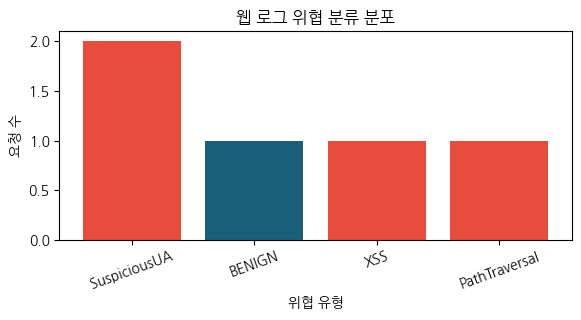

In [9]:
# 웹 로그 위협 분류 분포
import matplotlib.pyplot as plt
vc = web['threat'].value_counts()
colors = ['#1a5f7a' if k == 'BENIGN' else '#e74c3c' for k in vc.index]
fig, ax = plt.subplots(figsize=(6, 3.3))
ax.bar(vc.index.astype(str), vc.values, color=colors)
ax.set_title('웹 로그 위협 분류 분포')
ax.set_xlabel('위협 유형'); ax.set_ylabel('요청 수')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

---
## Step 5. 의심 IP 추출

In [10]:
suspect = (web[web['threat'] != 'BENIGN']
           .groupby('ip')['threat']
           .agg(['count', lambda x: list(set(x))])
           .rename(columns={'count':'n_alerts','<lambda_0>':'threats'})
           .sort_values('n_alerts', ascending=False))
suspect

,n_alerts,threats
ip,,
10.0.0.99,3,"[SuspiciousUA, PathTraversal]"
10.0.0.5,1,[XSS]


---
## 정리

- Zeek 의 uid 가 다중 로그를 묶는 join 키.
- 정규식 한 줄로 Apache 로그 파싱이 가능.
- SQLi/XSS/Path traversal 키워드 룰이 1차 탐지의 기본.
- 다음 챕터에서 이런 알람들을 SIEM 으로 상관 분석한다.